In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import control as ct
import scipy.signal as signal

In [3]:
K = 20
G1 = ct.tf([1], [1, 1])
G2 = ct.tf([1], [1, 3])
G3 = ct.tf([1], [1, 6])

# Gain of the system K 
print(f'The gain of the system K: {K}')

# Actual Plant 
G = K * G1 * G2 * G3
print(f'The transfer function of the system G(s): {G}')

# Feedback Loop Transfer Function
H = 1 
print(f'The transfer function of the feedback loop H(s): {H}')

# Open Loop Transfer Funtion 
L = G * H
print(f'The transfer function of the open loop system L(s): {L}')

# Closed Loop Transfer Funtion
CL = ct.feedback(G, H)
print(f'The transfer function of the closed loop system CL(s): {CL}')

The gain of the system K: 20
The transfer function of the system G(s): <TransferFunction>: sys[17]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

             20
  ------------------------
  s^3 + 10 s^2 + 27 s + 18
The transfer function of the feedback loop H(s): 1
The transfer function of the open loop system L(s): <TransferFunction>: sys[19]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

             20
  ------------------------
  s^3 + 10 s^2 + 27 s + 18
The transfer function of the closed loop system CL(s): <TransferFunction>: sys[21]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

             20
  ------------------------
  s^3 + 10 s^2 + 27 s + 38


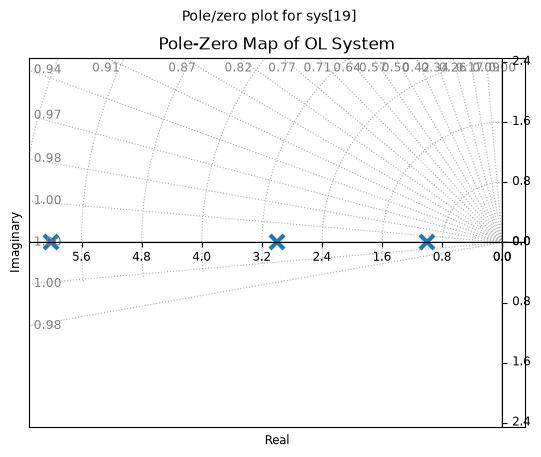

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


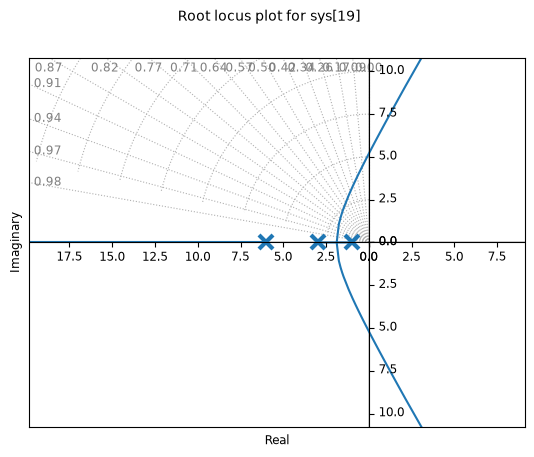

DC gain for OL= 1.1111111111111112
Zeros of OL= []
Poles of OL= [-6.+0.j -3.+0.j -1.+0.j]
Dominant stable OL pole(s): [-1.+0.j]
Dominant OL pole (p1) = (-1.0000000000000002+0j)
Dominant OL pole (p1) in abs value = 1.0000000000000002


In [4]:
# Plot the Pole-Zero map with the damping/frequency grid
ct.pole_zero_plot(L, grid=True, marker_size=10, marker_width=3)
plt.title("Pole-Zero Map of OL System")
plt.show()

# Root locus = drawn for open loop system to see closed loop poles location at s plane
ct.root_locus(L, grid=True, marker_size=10, marker_width=3) 
plt.show()

# DC gain 
dc = ct.dcgain(L)
print(f'DC gain for OL= {dc}')
# Zeros 
z = ct.zeros(L)
print(f'Zeros of OL= {z}')
# Poles 
p = ct.poles(L)
print(f'Poles of OL= {p}')

tol = 1e-8
# keep only strictly stable poles (real part < 0)
stable_mask = np.real(p) < -tol

if np.any(stable_mask):
    p_stable = p[stable_mask]
    rp = np.real(p_stable)
    max_rp = np.max(rp)
    dominant_poles = p_stable[np.isclose(rp, max_rp, atol=tol)]
else:
    dominant_poles = np.array([])
    print("No strictly stable pole -> no classical dominant pole.")

print("Dominant stable OL pole(s):", dominant_poles)

p1 = dominant_poles[0]
p_do = dominant_poles[0]
print(f'Dominant OL pole (p1) = {p1}')
print(f'Dominant OL pole (p1) in abs value = {np.abs(p1)}')

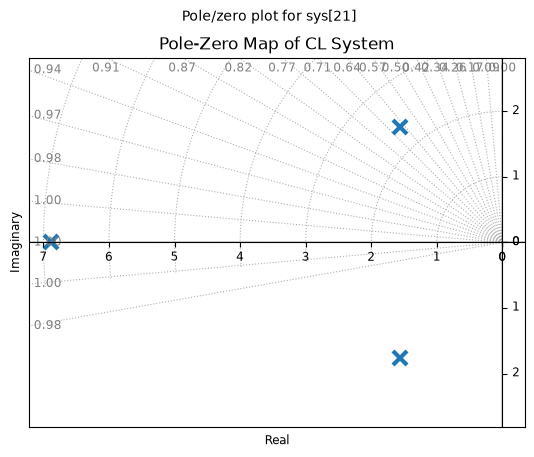

DC gain for CL= 0.5263157894736842
Zeros of CL= []
Poles of CL= [-6.87755644+0.j         -1.56122178+1.75721506j -1.56122178-1.75721506j]
    Eigenvalue (pole)       Damping     Frequency
               -6.878             1         6.878
    -1.561    +1.757j        0.6642         2.351
    -1.561    -1.757j        0.6642         2.351
Natural frequency of poles (Wn) = [6.87755644 2.35057827 2.35057827]
Damping ratio zeta of poles (Z) = [1.         0.66418626 0.66418626]
Poles = [-6.87755644+0.j         -1.56122178+1.75721506j -1.56122178-1.75721506j]
Poles of CL= [-6.87755644+0.j         -1.56122178+1.75721506j -1.56122178-1.75721506j]
Dominant stable CL pole(s): [-1.56122178+1.75721506j -1.56122178-1.75721506j]
Dominant CL pole (p1) = (-1.5612217786173255+1.7572150562013262j)
Dominant CL pole (p1) in abs value = 2.3505782683777356


Dominant Pole: (-1.5612217786173255+1.7572150562013262j)
Natural frequency (wn): 2.3505782683777356 rad/s
Damping ratio (zeta, z): 0.6641862556207546
Dec

In [5]:
# closed loop poles and zeros analysis 

# Plot the Pole-Zero map with the damping/frequency grid
ct.pole_zero_plot(CL, grid=True, marker_size=10, marker_width=3)
plt.title("Pole-Zero Map of CL System")
plt.show()

# DC gain 
dc = ct.dcgain(CL)
print(f'DC gain for CL= {dc}')
# Zeros 
z = ct.zeros(CL)
print(f'Zeros of CL= {z}')
# Poles 
p = ct.poles(CL)
print(f'Poles of CL= {p}')

# Print exact transient metrics derived from poles 
wn, zeta, poles = ct.damp(CL)
print(f'Natural frequency of poles (Wn) = {wn}')
print(f'Damping ratio zeta of poles (Z) = {zeta}')
print(f'Poles = {poles}')

# To find the dominant pole(s) of a control system plant, 
# you identify the poles (the roots of the denominator of the transfer function) that lie closest to the imaginary (jw) axis 
# or the origin in the s-plane, 
# provided other poles are sufficiently far away
print(f'Poles of CL= {p}')

tol = 1e-8
# keep only strictly stable poles (real part < 0)
stable_mask = np.real(p) < -tol

if np.any(stable_mask):
    p_stable = p[stable_mask]
    rp = np.real(p_stable)
    max_rp = np.max(rp)
    dominant_poles = p_stable[np.isclose(rp, max_rp, atol=tol)]
else:
    dominant_poles = np.array([])
    print("No strictly stable pole -> no classical dominant pole.")

print("Dominant stable CL pole(s):", dominant_poles)

p1 = dominant_poles[0]
p_d = dominant_poles[0]
print(f'Dominant CL pole (p1) = {p1}')
print(f'Dominant CL pole (p1) in abs value = {np.abs(p1)}')
print('\n')

wn = abs(p1)                  # Natural frequency (rad/s)
zeta = -np.real(p1) / wn     # Damping ratio
sigma = -np.real(p1)         # Decay rate (1/s)
wd = abs(np.imag(p1))        # Damped frequency (rad/s)

print("Dominant Pole:", p1)
print("Natural frequency (wn):", wn, "rad/s")
print("Damping ratio (zeta, z):", zeta)
print("Decay rate (sigma):", sigma, "1/s")
print("Damped frequency (wd):", wd, "rad/s")




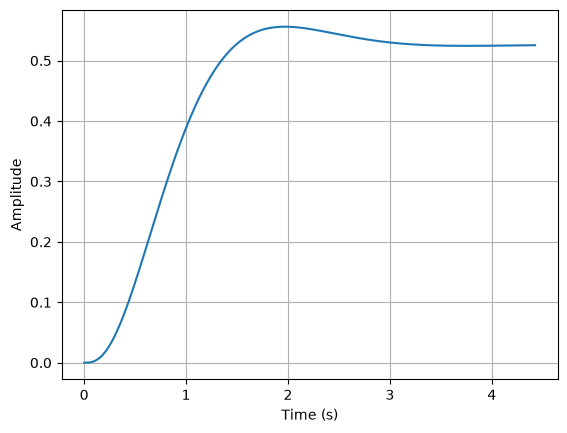

Rise Time (Tr): 0.90 seconds
Settling Time (Ts): 2.72 seconds
Peak Time (Tp): 1.96 seconds
Overshoot (%): 5.67%
Final Value = 0.5263157894736842
Steasy state error (ess) = 0.4736842105263158


In [6]:
plt.figure()
t, y = ct.step_response(CL)

plt.plot(t, y)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.show()

# transient characteristics
info = ct.step_info(CL)
final_value = info['SteadyStateValue']
ess = 1 - final_value


print(f"Rise Time (Tr): {info['RiseTime']:.2f} seconds")
print(f"Settling Time (Ts): {info['SettlingTime']:.2f} seconds")
print(f"Peak Time (Tp): {info['PeakTime']:.2f} seconds")
print(f"Overshoot (%): {info['Overshoot']:.2f}%")
# print(f"Undershoot (%): {info['Undershoot']:.2f}%")
print(f'Final Value = {info["SteadyStateValue"]}')
print(f'Steasy state error (ess) = {ess}')

In [7]:
# Type of the system = 0 
# So, Kp is specified, Kp = lim:s->0 G(s)Gc(s) 

Kp_old = np.abs(G(0))
print(f'Old velocity error constant (Kp_old) = {Kp_old}')

ess_old = 1/(Kp_old+1)
print(f'Old error (ess) = {ess_old}')

Old velocity error constant (Kp_old) = 1.1111111111111112
Old error (ess) = 0.47368421052631576


In [8]:
# Required Specification 
# ess = 0.01 

In [9]:
# Type of the system = 0
# So, Kp is specified, Kp = lim:s->0 G(s)Gc(s)

ess_new = 0.01 
print(f'Required error (ess) = {ess_new}')
Kp_new = (1 / ess_new) - 1 
print(f'Required velocity error constant (Kp_new) = {Kp_new}')

Required error (ess) = 0.01
Required velocity error constant (Kp_new) = 99.0


In [10]:
beta = Kp_new / Kp_old
print(f'Beta = {beta}')

# Nearest open loop pole
# -1/T = 10% of the nearest open or close loop pole
# P_do  np.real(p_do)
T = -1/(0.1*np.real(p_do))
print(f'T = {T}')

zc = 1/T
print(f'Zero of the lag compensator (zc) = {zc}')
pc = 1/(T*beta)
print(f'Pole of the lag compensator (pc) = {pc}')

# Lag Compensator transfer function without gain 
Gc = ct.tf([1, zc], [1, pc])
print(f'Lead Compensator Transfer Function without gain (Gc) = {Gc}')

# |Gc(s)| = 1 and -5 < angle(Gc(s)) < 0 
print(f'Open Loop Gain at required Pole Gc(Sd) = {Gc(p_do)}')
print(f'Open Loop Gain at required Pole in absolute form Gc(Sd) = {np.abs(Gc(p_do))}')
print(f'Open Loop Phase at required Pole Gc(Sd) = {np.angle(Gc(p_do))}')
print(f'Open Loop Phase at required Pole in Degrees Gc(Sd) = {np.rad2deg(np.angle(Gc(p_do)))}')

Beta = 89.1
T = 9.999999999999996
Zero of the lag compensator (zc) = 0.10000000000000003
Pole of the lag compensator (pc) = 0.0011223344556677895
Lead Compensator Transfer Function without gain (Gc) = <TransferFunction>: sys[26]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

    s + 0.1
  ------------
  s + 0.001122
Open Loop Gain at required Pole Gc(Sd) = (0.9010112359550561-0j)
Open Loop Gain at required Pole in absolute form Gc(Sd) = 0.9010112359550561
Open Loop Phase at required Pole Gc(Sd) = -0.0
Open Loop Phase at required Pole in Degrees Gc(Sd) = -0.0


In [11]:
# Lead compensator gain 
Kc = 1/(np.abs(G(p_d)*Gc(p_d)))
print(f'Lead Compensator Gain (Kc) = {Kc}')

Lead Compensator Gain (Kc) = 1.028201112335581


In [12]:
Gc1 = Kc * Gc
print(f'Lead Compensator Transfer Function with gain (Gc1) = {Gc1}')

# |Gc(s)| = 1 and -5 < angle(Gc(s)) < 0 
print(f'Open Loop Gain at required Pole G(Sd) = {Gc(p_d)}')
print(f'Open Loop Gain at required Pole in absolute form G(Sd) = {np.abs(Gc(p_d))}')
print(f'Open Loop Phase at required Pole G(Sd) = {np.angle(Gc(p_d))}')
print(f'Open Loop Phase at required Pole in Degrees G(Sd) = {np.rad2deg(np.angle(Gc(p_d)))}')

Lead Compensator Transfer Function with gain (Gc1) = <TransferFunction>: sys[28]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

  1.028 s + 0.1028
  ----------------
    s + 0.001122
Open Loop Gain at required Pole G(Sd) = (0.9720632103913407-0.0314665501010063j)
Open Loop Gain at required Pole in absolute form G(Sd) = 0.9725723771378554
Open Loop Phase at required Pole G(Sd) = -0.03235958903907638
Open Loop Phase at required Pole in Degrees G(Sd) = -1.8540678787168758


In [13]:
# Type of system = 1 i.e. pole at origin = 1 
# so the velocity error constant, Kv = lim:s->0 sG(s)Gc(s)
kp = np.abs(G(0)*Gc1(0))
print(f'velocity error constant kp = {kp}')

ess = 1/(kp+1)
print(f'steady state error ess = {ess}')

velocity error constant kp = 101.79191012122251
steady state error ess = 0.009728392038057273


In [14]:
A3 = G*Gc1 
print(f'System Transfer Function with compensator A3(s) = {A3}')
A4 = A3 * H
print(f'open loop system transfer function with compensator A4(s) = {A4}')
A5 = ct.feedback(A3, 1)
print(f'Closed loop system transfer function with compensator A5(s) = {A5}')

System Transfer Function with compensator A3(s) = <TransferFunction>: sys[29]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

                20.56 s + 2.056
  -------------------------------------------
  s^4 + 10 s^3 + 27.01 s^2 + 18.03 s + 0.0202
open loop system transfer function with compensator A4(s) = <TransferFunction>: sys[31]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

                20.56 s + 2.056
  -------------------------------------------
  s^4 + 10 s^3 + 27.01 s^2 + 18.03 s + 0.0202
Closed loop system transfer function with compensator A5(s) = <TransferFunction>: sys[33]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

               20.56 s + 2.056
  ------------------------------------------
  s^4 + 10 s^3 + 27.01 s^2 + 38.59 s + 2.077


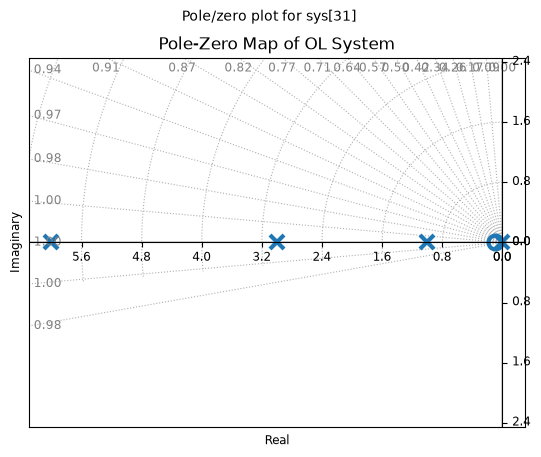

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


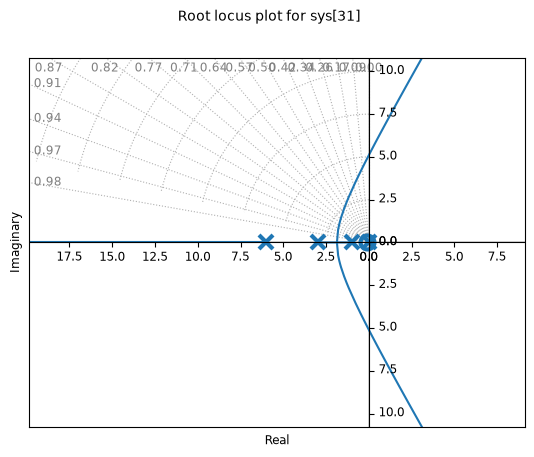

DC gain for OL= 101.79191012122251
Zeros of OL= [-0.1+0.j]
Poles of OL= [-6.00000000e+00+0.j -3.00000000e+00+0.j -1.00000000e+00+0.j
 -1.12233446e-03+0.j]
Dominant stable OL pole(s): [-0.00112233+0.j]
Dominant OL pole (p1) = (-0.0011223344556677897+0j)
Dominant OL pole (p1) in abs value = 0.0011223344556677897


In [15]:
# Plot the Pole-Zero map with the damping/frequency grid
ct.pole_zero_plot(A4, grid=True, marker_size=10, marker_width=3)
plt.title("Pole-Zero Map of OL System")
plt.show()

# Root locus = drawn for open loop system to see closed loop poles location at s plane
ct.root_locus(A4, grid=True, marker_size=10, marker_width=3) 
plt.show()

# DC gain 
dc = ct.dcgain(A4)
print(f'DC gain for OL= {dc}')
# Zeros 
z = ct.zeros(A4)
print(f'Zeros of OL= {z}')
# Poles 
p = ct.poles(A4)
print(f'Poles of OL= {p}')

tol = 1e-8
# keep only strictly stable poles (real part < 0)
stable_mask = np.real(p) < -tol

if np.any(stable_mask):
    p_stable = p[stable_mask]
    rp = np.real(p_stable)
    max_rp = np.max(rp)
    dominant_poles = p_stable[np.isclose(rp, max_rp, atol=tol)]
else:
    dominant_poles = np.array([])
    print("No strictly stable pole -> no classical dominant pole.")

print("Dominant stable OL pole(s):", dominant_poles)

p1 = dominant_poles[0]
print(f'Dominant OL pole (p1) = {p1}')
print(f'Dominant OL pole (p1) in abs value = {np.abs(p1)}')

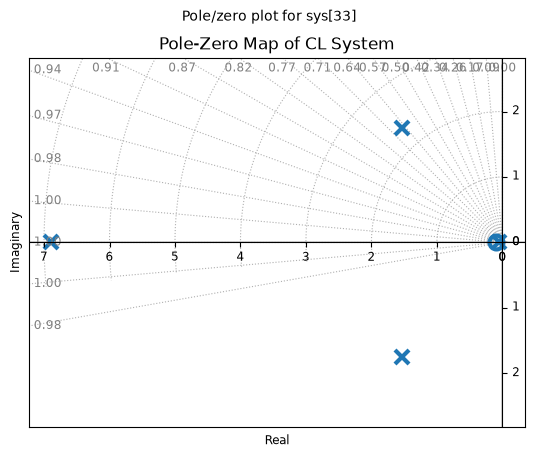

DC gain for CL= 0.9902716079619426
Zeros of CL= [-0.1+0.j]
Poles of CL= [-6.88610213+0.j         -1.52953418+1.74649385j -1.52953418-1.74649385j
 -0.05595185+0.j        ]
    Eigenvalue (pole)       Damping     Frequency
               -6.886             1         6.886
     -1.53    +1.746j        0.6588         2.322
     -1.53    -1.746j        0.6588         2.322
             -0.05595             1       0.05595
Natural frequency of poles (Wn) = [6.88610213 2.3215761  2.3215761  0.05595185]
Damping ratio zeta of poles (Z) = [1.         0.65883439 0.65883439 1.        ]
Poles = [-6.88610213+0.j         -1.52953418+1.74649385j -1.52953418-1.74649385j
 -0.05595185+0.j        ]
Poles of CL= [-6.88610213+0.j         -1.52953418+1.74649385j -1.52953418-1.74649385j
 -0.05595185+0.j        ]
Dominant stable CL pole(s): [-0.05595185+0.j]
Dominant CL pole (p1) = (-0.055951847454398095+0j)
Dominant CL pole (p1) in abs value = 0.055951847454398095


Dominant Pole: (-0.055951847454398095+0j)
N

In [16]:
# closed loop poles and zeros analysis 

# Plot the Pole-Zero map with the damping/frequency grid
ct.pole_zero_plot(A5, grid=True, marker_size=10, marker_width=3)
plt.title("Pole-Zero Map of CL System")
plt.show()

# DC gain 
dc = ct.dcgain(A5)
print(f'DC gain for CL= {dc}')
# Zeros 
z = ct.zeros(A5)
print(f'Zeros of CL= {z}')
# Poles 
p = ct.poles(A5)
print(f'Poles of CL= {p}')

# Print exact transient metrics derived from poles 
wn, zeta, poles = ct.damp(A5)
print(f'Natural frequency of poles (Wn) = {wn}')
print(f'Damping ratio zeta of poles (Z) = {zeta}')
print(f'Poles = {poles}')

# To find the dominant pole(s) of a control system plant, 
# you identify the poles (the roots of the denominator of the transfer function) that lie closest to the imaginary (jw) axis 
# or the origin in the s-plane, 
# provided other poles are sufficiently far away
print(f'Poles of CL= {p}')

tol = 1e-8
# keep only strictly stable poles (real part < 0)
stable_mask = np.real(p) < -tol

if np.any(stable_mask):
    p_stable = p[stable_mask]
    rp = np.real(p_stable)
    max_rp = np.max(rp)
    dominant_poles = p_stable[np.isclose(rp, max_rp, atol=tol)]
else:
    dominant_poles = np.array([])
    print("No strictly stable pole -> no classical dominant pole.")

print("Dominant stable CL pole(s):", dominant_poles)

p1 = dominant_poles[0]
print(f'Dominant CL pole (p1) = {p1}')
print(f'Dominant CL pole (p1) in abs value = {np.abs(p1)}')
print('\n')

wn = abs(p1)                  # Natural frequency (rad/s)
zeta = -np.real(p1) / wn     # Damping ratio
sigma = -np.real(p1)         # Decay rate (1/s)
wd = abs(np.imag(p1))        # Damped frequency (rad/s)

print("Dominant Pole:", p1)
print("Natural frequency (wn):", wn, "rad/s")
print("Damping ratio (zeta, z):", zeta)
print("Decay rate (sigma):", sigma, "1/s")
print("Damped frequency (wd):", wd, "rad/s")




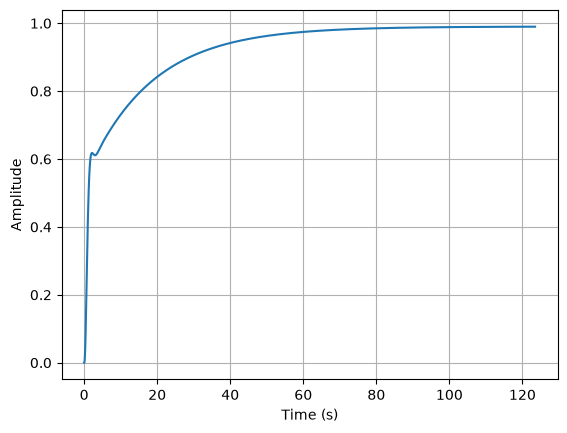

Rise Time (Tr): 26.77 seconds
Settling Time (Ts): 55.99 seconds
Peak Time (Tp): 123.46 seconds
Overshoot (%): 0.00%
Final Value = 0.9902716079619426
Steasy state error (ess) = 0.00972839203805742


In [17]:
plt.figure()
t, y = ct.step_response(A5)

plt.plot(t, y)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.show()

# transient characteristics
info = ct.step_info(A5)
final_value = info['SteadyStateValue']
ess = 1 - final_value


print(f"Rise Time (Tr): {info['RiseTime']:.2f} seconds")
print(f"Settling Time (Ts): {info['SettlingTime']:.2f} seconds")
print(f"Peak Time (Tp): {info['PeakTime']:.2f} seconds")
print(f"Overshoot (%): {info['Overshoot']:.2f}%")
# print(f"Undershoot (%): {info['Undershoot']:.2f}%")
print(f'Final Value = {info["SteadyStateValue"]}')
print(f'Steasy state error (ess) = {ess}')

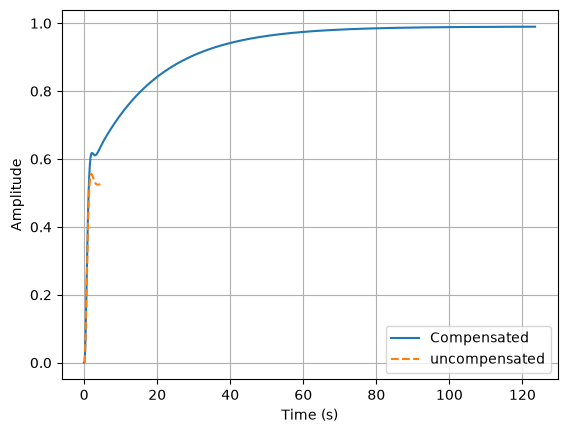

In [18]:
plt.figure()
t1, y1 = ct.step_response(A5)
t2, y2 = ct.step_response(CL)

plt.plot(t1, y1, label='Compensated')
plt.plot(t2, y2, label='uncompensated', linestyle='--')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.legend()
plt.show()